In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from collections import Counter
from nltk import bigrams
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support, classification_report

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from wordcloud import WordCloud

In [22]:
# Baca dataset
df = pd.read_csv('/content/drive/MyDrive/SKRIPSI/data_opini_preprocessed.csv')
df.head()

,text,stance,label
0,ada food estate papua manfaat masyarakat penuh...,0,Pro
1,tanah papua semangat mandiri pangan indonesia ...,0,Pro
2,papua kembang pesat wilayah strategis daerah t...,3,Netral
3,kaya alam budaya timur indonesia simbol kuat b...,3,Netral
4,food estate merauke bukti bangun inklusif manu...,0,Pro


# **EXPLORATORY DATA ANALYSIS (EDA)**

## **distribusi label**

label
Kontra    382
Pro       376
Netral    253
Name: count, dtype: int64


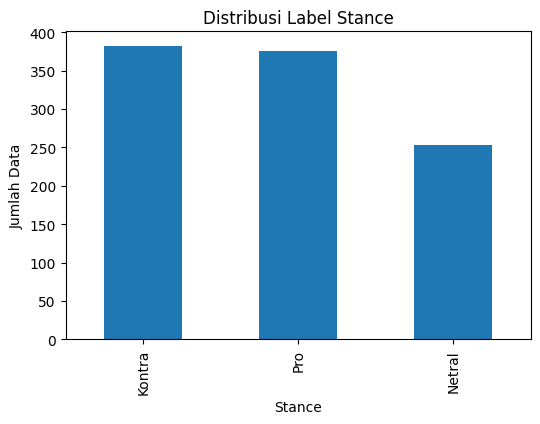

In [ ]:
stance_counts = df['label'].value_counts()

print(stance_counts)

plt.figure(figsize=(6,4))
stance_counts.plot(kind='bar')
plt.title('Distribusi Label Stance')
plt.xlabel('Stance')
plt.ylabel('Jumlah Data')
plt.show()

##**pie chart distribusi**

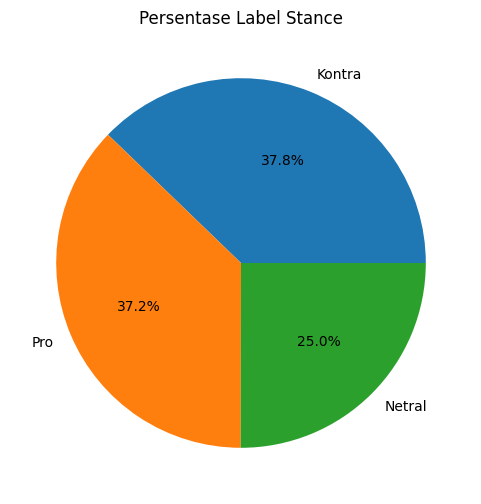

In [ ]:
plt.figure(figsize=(6,6))
df['label'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)
plt.ylabel('')
plt.title('Persentase Label Stance')
plt.show()

##**distribusi panjang komentar**

In [ ]:
df['word_count'] = df['text'].astype(str).apply(lambda x: len(x.split()))

df['word_count'].describe()

,word_count
count,1011.000000
mean,12.293769
std,9.321313
min,1.000000
25%,6.000000
50%,10.000000
75%,16.000000
max,102.000000


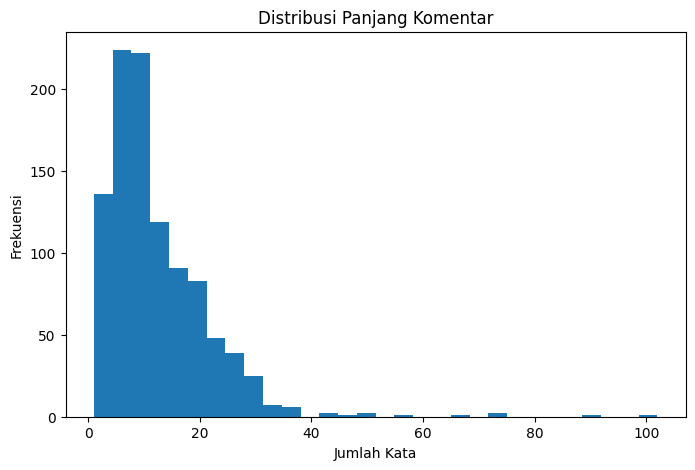

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['word_count'], bins=30)
plt.title('Distribusi Panjang Komentar')
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.show()

##**wordcloud label pro**

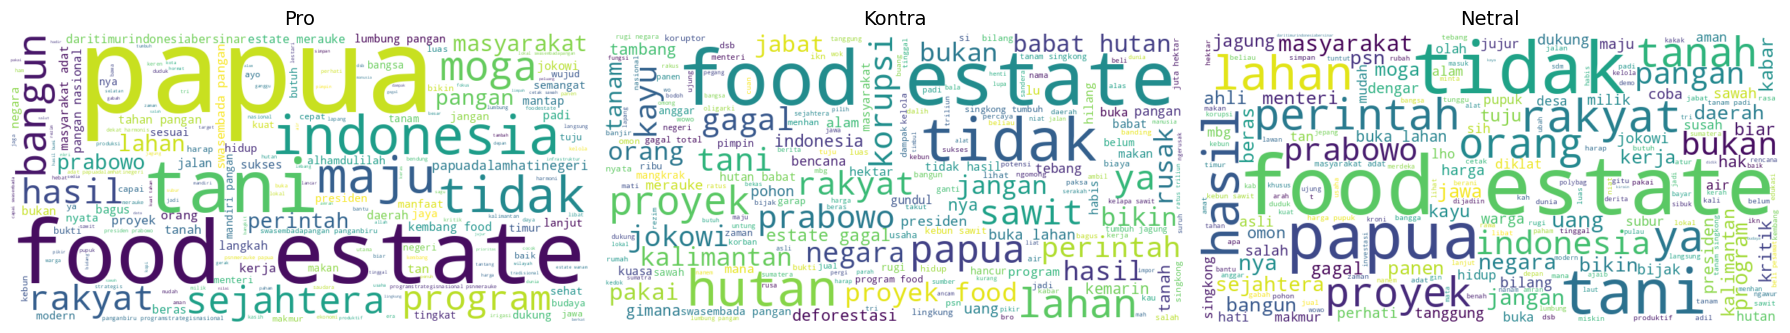

In [ ]:
texts = {
    'Pro': ' '.join(df[df['label']=='Pro']['text'].astype(str)),
    'Kontra': ' '.join(df[df['label']=='Kontra']['text'].astype(str)),
    'Netral': ' '.join(df[df['label']=='Netral']['text'].astype(str))
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (label, text) in zip(axes, texts.items()):
    wc = WordCloud(
        width=800,
        height=400,
        background_color='white'
    ).generate(text)

    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(label, fontsize=14)
    ax.axis('off')

plt.tight_layout()
plt.show()

##**top 20 kata per stance**

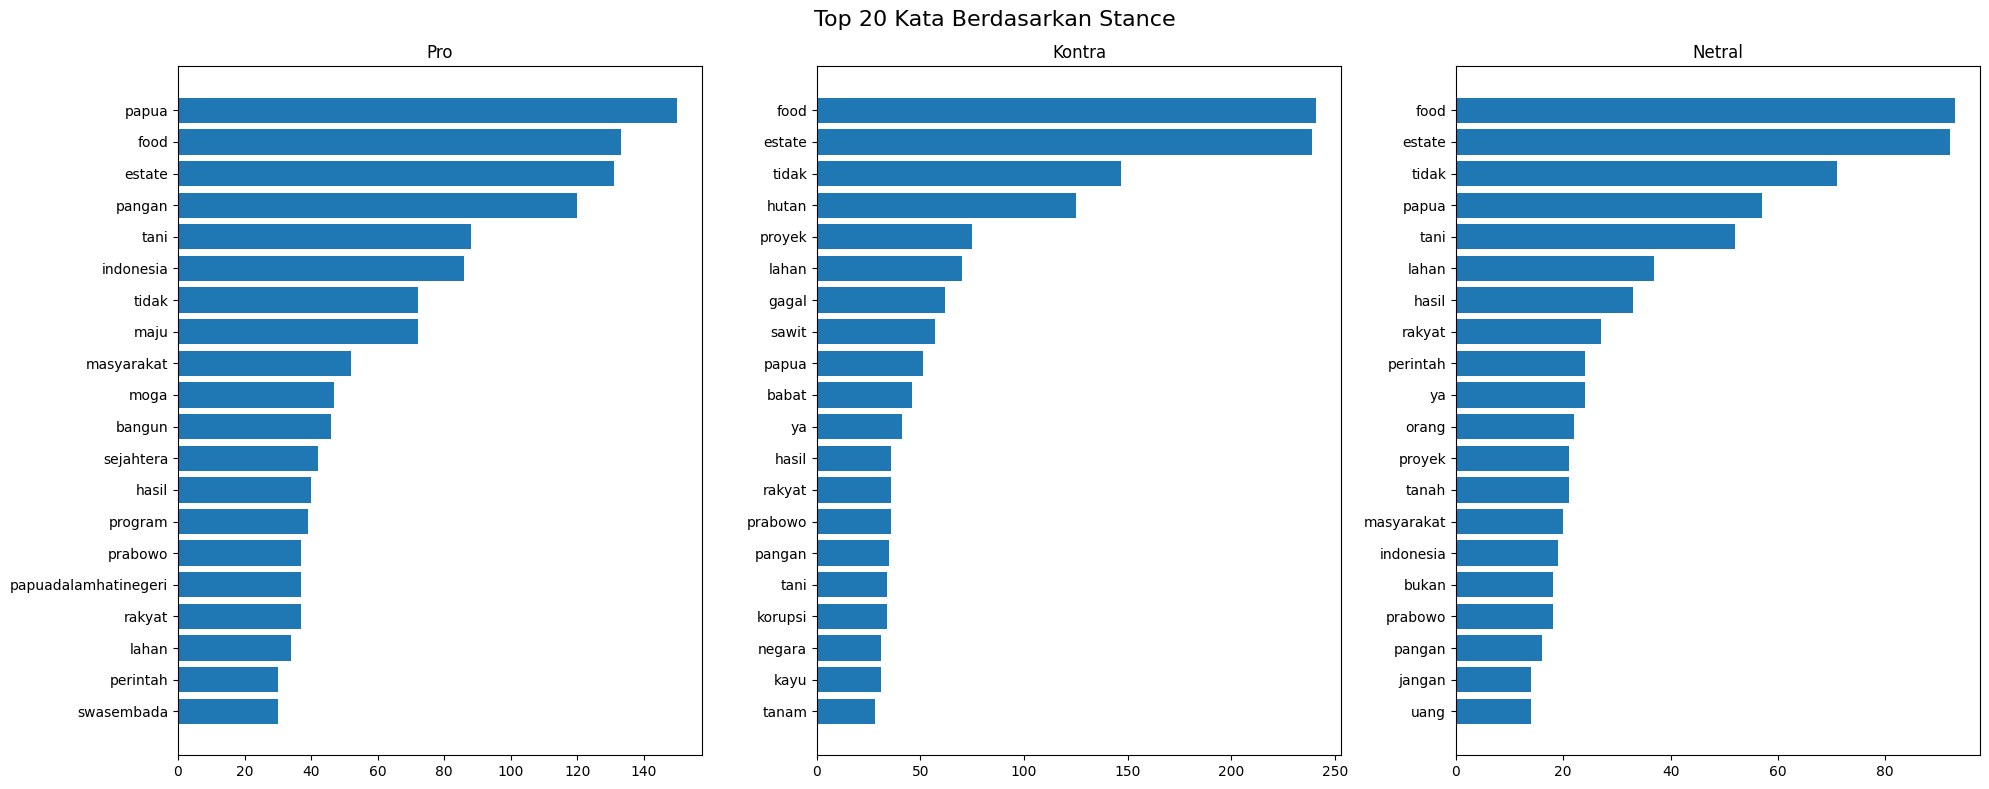

In [ ]:
# Fungsi mengambil top words
def get_top_words(text_series, n=20):
    words = ' '.join(text_series.astype(str)).split()
    return pd.DataFrame(
        Counter(words).most_common(n),
        columns=['kata', 'frekuensi']
    )

# Ambil top words masing-masing stance
pro_df = get_top_words(
    df[df['label'] == 'Pro']['text']
)

kontra_df = get_top_words(
    df[df['label'] == 'Kontra']['text']
)

netral_df = get_top_words(
    df[df['label'] == 'Netral']['text']
)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Pro
axes[0].barh(
    pro_df['kata'],
    pro_df['frekuensi']
)
axes[0].set_title('Pro')
axes[0].invert_yaxis()

# Kontra
axes[1].barh(
    kontra_df['kata'],
    kontra_df['frekuensi']
)
axes[1].set_title('Kontra')
axes[1].invert_yaxis()

# Netral
axes[2].barh(
    netral_df['kata'],
    netral_df['frekuensi']
)
axes[2].set_title('Netral')
axes[2].invert_yaxis()

plt.suptitle(
    'Top 20 Kata Berdasarkan Stance',
    fontsize=16
)

plt.tight_layout()
plt.show()

##**top 10 bigram**

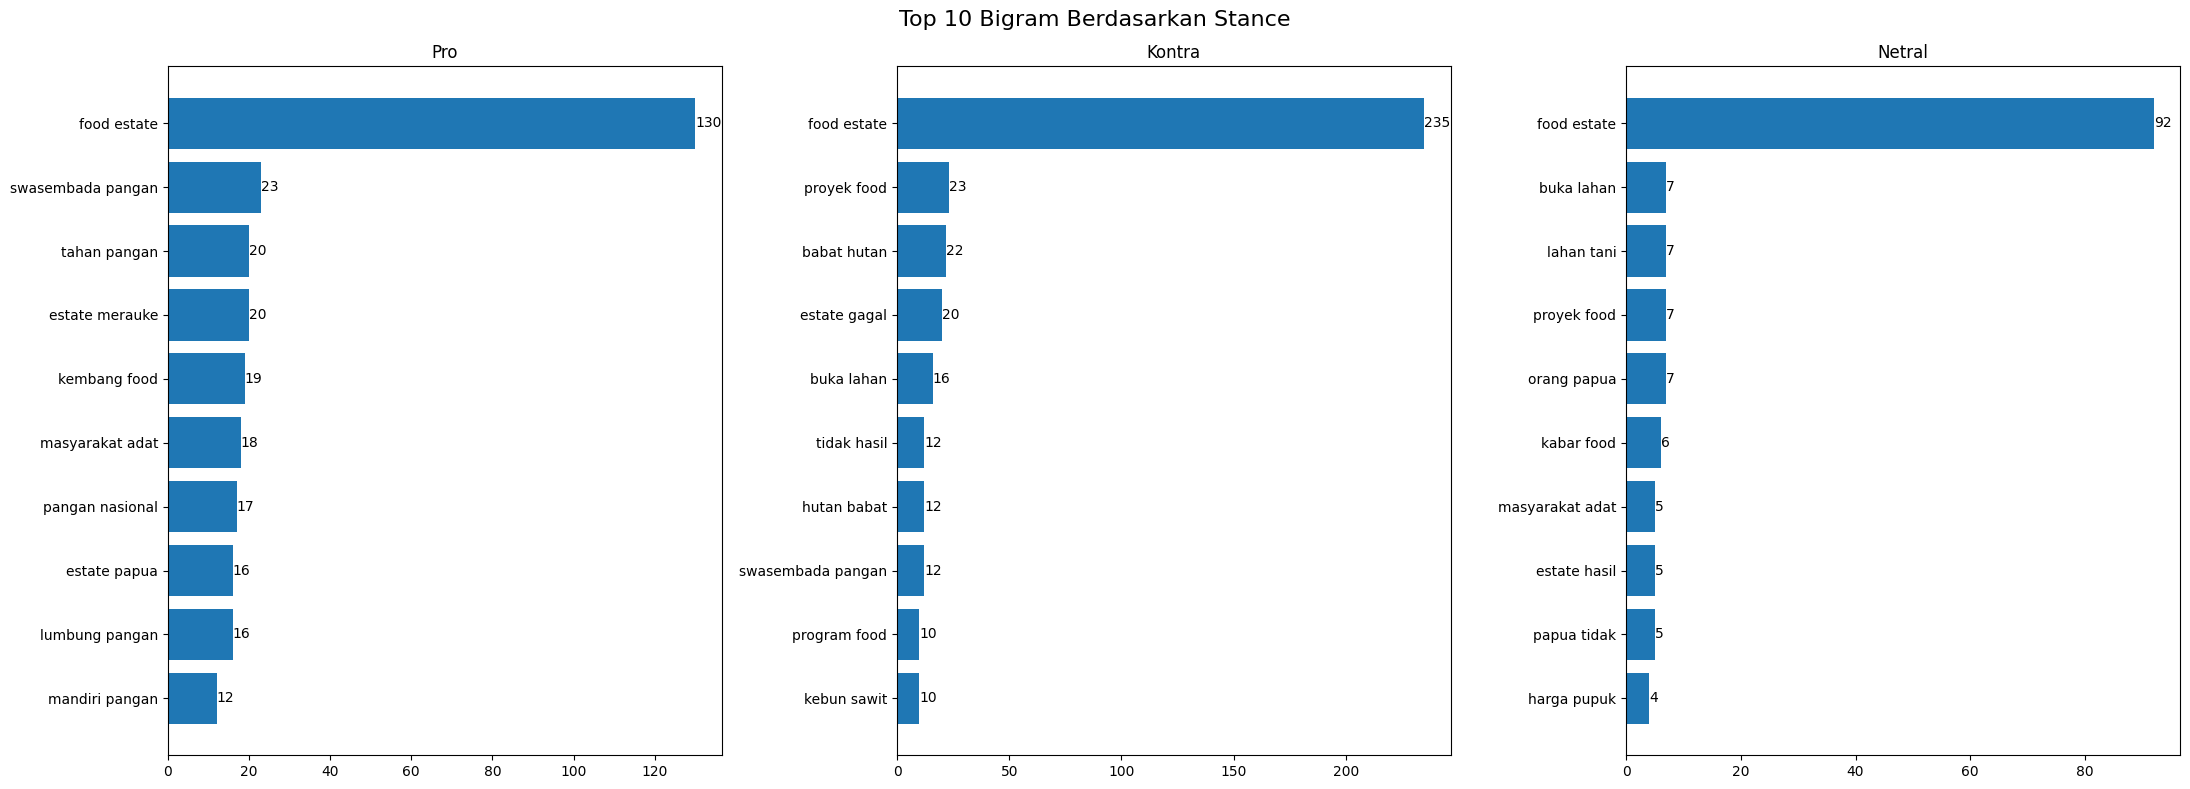

In [ ]:
# Fungsi mengambil top bigram
def get_top_bigrams(text_series, n=10):

    words = ' '.join(
        text_series.astype(str)
    ).split()

    bigram_freq = Counter(
        bigrams(words)
    ).most_common(n)

    bigram_df = pd.DataFrame(
        bigram_freq,
        columns=['bigram', 'frekuensi']
    )

    bigram_df['bigram'] = bigram_df['bigram'].apply(
        lambda x: ' '.join(x)
    )

    return bigram_df

# Ambil bigram tiap stance
pro_bigram = get_top_bigrams(
    df[df['label'] == 'Pro']['text']
)

kontra_bigram = get_top_bigrams(
    df[df['label'] == 'Kontra']['text']
)

netral_bigram = get_top_bigrams(
    df[df['label'] == 'Netral']['text']
)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

# PRO
axes[0].barh(
    pro_bigram['bigram'],
    pro_bigram['frekuensi']
)
axes[0].set_title('Pro')
axes[0].invert_yaxis()

for i, v in enumerate(pro_bigram['frekuensi']):
    axes[0].text(v, i, str(v), va='center')

# KONTRA
axes[1].barh(
    kontra_bigram['bigram'],
    kontra_bigram['frekuensi']
)
axes[1].set_title('Kontra')
axes[1].invert_yaxis()

for i, v in enumerate(kontra_bigram['frekuensi']):
    axes[1].text(v, i, str(v), va='center')

# NETRAL
axes[2].barh(
    netral_bigram['bigram'],
    netral_bigram['frekuensi']
)
axes[2].set_title('Netral')
axes[2].invert_yaxis()

for i, v in enumerate(netral_bigram['frekuensi']):
    axes[2].text(v, i, str(v), va='center')

plt.suptitle(
    'Top 10 Bigram Berdasarkan Stance',
    fontsize=16
)

plt.tight_layout()
plt.show()

##**jumlah kata sebelum dan sesudah preprocessing**

In [ ]:
raw_df = pd.read_csv('/content/drive/MyDrive/SKRIPSI/data_opini.csv')
raw_words = raw_df['text'].astype(str).str.split().str.len().sum()

clean_words = df['text'].astype(str).str.split().str.len().sum()

print("Sebelum:", raw_words)
print("Sesudah:", clean_words)

Sebelum: 20412
Sesudah: 12429


In [ ]:
print("Jumlah Data :", len(df))

print("Jumlah Pro :",
      len(df[df['stance']==0]))

print("Jumlah Kontra :",
      len(df[df['stance']==2]))

print("Jumlah Netral :",
      len(df[df['stance']==3]))

print("Rata-rata kata :",
      round(df['word_count'].mean(),2))

print("Komentar terpanjang :",
      df['word_count'].max())

print("Komentar terpendek :",
      df['word_count'].min())

Jumlah Data : 1011
Jumlah Pro : 376
Jumlah Kontra : 382
Jumlah Netral : 253
Rata-rata kata : 12.29
Komentar terpanjang : 102
Komentar terpendek : 1


#**FEATURE EXTRACTION**

In [23]:
df = df.dropna(subset=['text'])
X = df['text']
y = df['stance']

tfidf = TfidfVectorizer(
    ngram_range=(1,2),
    max_features=5000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_tfidf = tfidf.fit_transform(X)

print(X_tfidf.shape)

(1010, 1870)


In [24]:
feature_names = tfidf.get_feature_names_out()

print(feature_names[:50])

['abadi' 'abai' 'aceh' 'ada' 'adat' 'adat ganggu' 'adat hilang'
 'adat papuadalamhatinegeri' 'adik' 'adil' 'adil sosial' 'aduh' 'agama'
 'ah' 'ahli' 'ahli proyek' 'ai' 'air' 'air lancar' 'air tidak' 'ajaib'
 'ajar' 'ajar bencana' 'akademisi' 'akal' 'akar' 'akibat' 'akibat proyek'
 'alam' 'alami' 'alamiin' 'alas' 'alas food' 'alat' 'alat modern'
 'alhamdulilah' 'alhamdulilah papua' 'alih' 'alih fungsi' 'alir' 'allah'
 'alutsista' 'alutsista food' 'aman' 'aman sejahtera' 'amat' 'ambil'
 'ambisi' 'amin' 'ampas']


In [25]:
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    columns=tfidf.get_feature_names_out()
)

tfidf_df.head()

,abadi,abai,aceh,ada,adat,adat ganggu,adat hilang,adat papuadalamhatinegeri,adik,adil,...,ya prabowo,ya tidak,ya tuju,yaa,yah,zaman,zaman harto,zaman jokowi,zaman prabowo,zaman soeharto
0,0.0,0.0,0.0,0.323475,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
X_tfidf = tfidf.fit_transform(df['text'])

print(X_tfidf.shape)

(1010, 1870)


# **DATA SPLIT**

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#**STRATIFIED CROSS VALIDATION**

In [28]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

all_y_true = []
all_y_pred = []

acc_scores = []
prec_scores = []
rec_scores = []
f1_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):

    X_fold_train = X_train[train_idx]
    X_fold_val = X_train[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    selector = SelectKBest(
        score_func=chi2,
        k=2000
    )

    X_fold_train_fs = selector.fit_transform(
        X_fold_train,
        y_fold_train
    )

    X_fold_val_fs = selector.transform(
        X_fold_val
    )

    model = LinearSVC(
        C=1,
        class_weight='balanced',
        random_state=42
    )

    model.fit(
        X_fold_train_fs,
        y_fold_train
    )

    y_pred = model.predict(X_fold_val_fs)

    all_y_true.extend(y_fold_val)
    all_y_pred.extend(y_pred)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_fold_val,
        y_pred,
        average='weighted'
    )

    acc = accuracy_score(
        y_fold_val,
        y_pred
    )

    acc_scores.append(acc)
    prec_scores.append(precision)
    rec_scores.append(recall)
    f1_scores.append(f1)

    print(f"Fold {fold}")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print()

Fold 1
Accuracy : 0.6667
Precision: 0.6624
Recall   : 0.6667
F1-Score : 0.6642

Fold 2
Accuracy : 0.6852
Precision: 0.6798
Recall   : 0.6852
F1-Score : 0.6813

Fold 3
Accuracy : 0.6852
Precision: 0.6618
Recall   : 0.6852
F1-Score : 0.6624

Fold 4
Accuracy : 0.6584
Precision: 0.6569
Recall   : 0.6584
F1-Score : 0.6574

Fold 5
Accuracy : 0.6149
Precision: 0.6081
Recall   : 0.6149
F1-Score : 0.6112



/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1870. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1870. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1870. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1870. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1870. All the features will be returned.
  warnings.w

In [29]:
print("=== Rata-rata 5 Fold ===")
print("Accuracy :", np.mean(acc_scores))
print("Precision:", np.mean(prec_scores))
print("Recall   :", np.mean(rec_scores))
print("F1-Score :", np.mean(f1_scores))

=== Rata-rata 5 Fold ===
Accuracy : 0.6620657925005752
Precision: 0.6538029036777703
Recall   : 0.6620657925005752
F1-Score : 0.6553209698513174


In [30]:
selector = SelectKBest(
    score_func=chi2,
    k=2000
)

X_train_fs = selector.fit_transform(
    X_train,
    y_train
)

X_test_fs = selector.transform(
    X_test
)

/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=2000 is greater than n_features=1870. All the features will be returned.
  warnings.warn(


# **MODEL TRAINING**

In [31]:
model = LinearSVC(
    C=1,
    class_weight='balanced',
    random_state=42
)

model.fit(
    X_train_fs,
    y_train
)

y_test_pred = model.predict(X_test_fs)

In [32]:
print("=== HASIL EVALUASI TEST SET (20%) ===")

print(
    classification_report(
        y_test,
        y_test_pred,
        digits=4
    )
)

accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(
    y_test,
    y_test_pred,
    average='weighted'
)
recall = recall_score(
    y_test,
    y_test_pred,
    average='weighted'
)
f1 = f1_score(
    y_test,
    y_test_pred,
    average='weighted'
)

print(f"Accuracy : {accuracy*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall   : {recall*100:.2f}%")
print(f"F1-Score : {f1*100:.2f}%")

=== HASIL EVALUASI TEST SET (20%) ===
              precision    recall  f1-score   support

           0     0.8052    0.8267    0.8158        75
           2     0.6591    0.7632    0.7073        76
           3     0.5135    0.3725    0.4318        51

    accuracy                         0.6881       202
   macro avg     0.6593    0.6541    0.6516       202
weighted avg     0.6766    0.6881    0.6780       202

Accuracy : 68.81%
Precision: 67.66%
Recall   : 68.81%
F1-Score : 67.80%


In [33]:
print("=== HASIL STRATIFIED 5-FOLD CROSS VALIDATION ===")

print(
    classification_report(
        all_y_true,
        all_y_pred,
        digits=4
    )
)

accuracy = accuracy_score(all_y_true, all_y_pred)
precision = precision_score(all_y_true, all_y_pred, average="weighted")
recall = recall_score(all_y_true, all_y_pred, average="weighted")
f1 = f1_score(all_y_true, all_y_pred, average="weighted")

print("\n=== HASIL AKHIR MODEL MENGGUNAKAN STRATIFIED 5-FOLD ===")
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1-Score  : {f1*100:.2f}%")

=== HASIL STRATIFIED 5-FOLD CROSS VALIDATION ===
              precision    recall  f1-score   support

           0     0.7500    0.7700    0.7599       300
           2     0.6758    0.7288    0.7013       306
           3     0.4765    0.4010    0.4355       202

    accuracy                         0.6621       808
   macro avg     0.6341    0.6332    0.6322       808
weighted avg     0.6535    0.6621    0.6566       808


=== HASIL AKHIR MODEL MENGGUNAKAN STRATIFIED 5-FOLD ===
Accuracy  : 66.21%
Precision : 65.35%
Recall    : 66.21%
F1-Score  : 65.66%


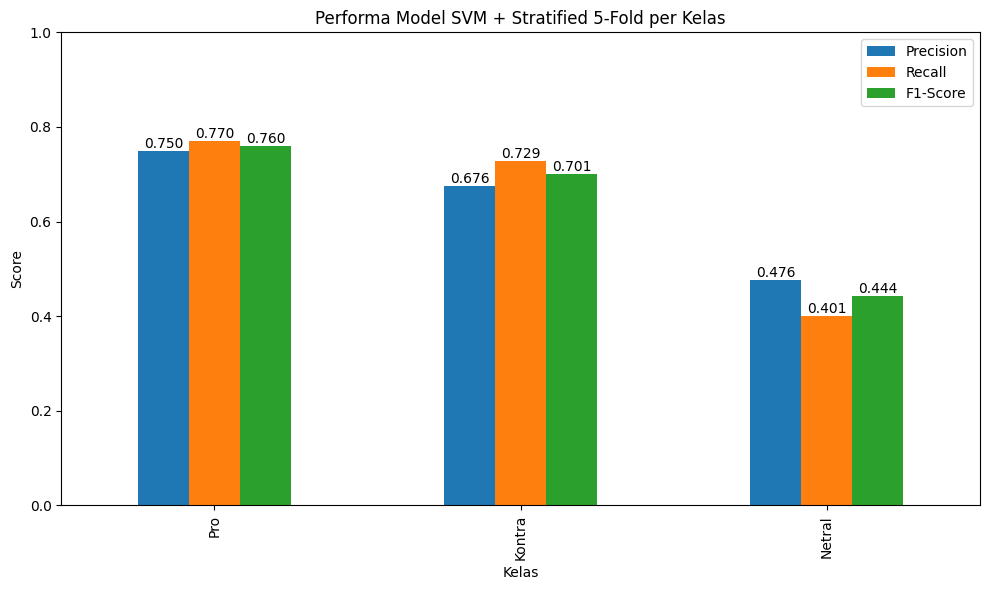

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Data dari classification report
df_metrics = pd.DataFrame({
    'Precision': [0.7500, 0.6758, 0.4765],
    'Recall':    [0.7700, 0.7288, 0.4010],
    'F1-Score':  [0.7599, 0.7013, 0.44355]
}, index=['Pro', 'Kontra', 'Netral'])

# Plot
ax = df_metrics.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Performa Model SVM + Stratified 5-Fold per Kelas')
plt.ylabel('Score')
plt.xlabel('Kelas')
plt.ylim(0, 1)
plt.legend(loc='upper right')

# Menampilkan nilai di atas batang
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f')

plt.tight_layout()
plt.show()

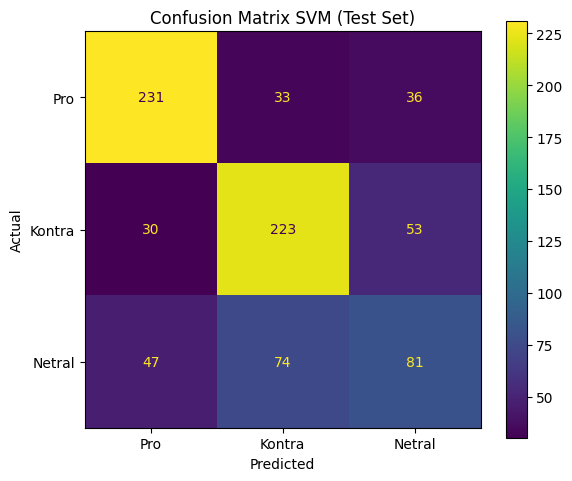

In [16]:
cm = confusion_matrix(all_y_true, all_y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pro", "Kontra", "Netral"]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(cmap="viridis", ax=ax)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix SVM (Test Set)")

plt.tight_layout()
plt.show()